In [1]:
from invisible_cities.cities.components import deconv_pmt, calibrate_pmts, get_pmt_wfs, load_dst, wf_from_files, WfType
from invisible_cities.core.core_functions import in_range
from invisible_cities.database  import load_db
import pandas as pd
import numpy as np
import tables as tb
import os
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from mpl_interactions import ioff, panhandler, zoom_factory
# from ipywidgets import interact, IntSlider
# import ipywidgets as widgets
from scipy.signal import find_peaks
# from scipy.signal import wiener
# from scipy.signal import butter, filtfilt
from pathlib  import Path
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
import sys
from datetime import datetime
from scipy.stats import trim_mean

%matplotlib widget

In [2]:
def find_highest_wf(wfs, event_number):
    assert len(wfs.shape) == 3, "input must be 3-dimensional"

    wfs   = wfs[event_number]
    wfs[16] = np.arange(wfs[16] .size) * 0
    index = np.argmax(np.max(wfs, axis=1))
    print(index)
    return wfs[index]

def find_highest_sipm(wfs, event_number):
    assert len(wfs.shape) == 3, "input must be 3-dimensional"

    wfs   = wfs[event_number]
    index = np.argmax(np.max(wfs, axis=1))
    print(index)
    return index

def sum_wf1(wfs, event_number):
    assert len(wfs.shape) == 3, "input must be 3-dimensional"

    wfs   = wfs[event_number]

    element_wise_sum = np.zeros_like(wfs[0],dtype=np.int64)

    # Sum the arrays element-wise
    for array in wfs:
        element_wise_sum += array

    return element_wise_sum

def sum_wf(wfs):
    element_wise_sum = np.zeros_like(wfs[0])

    # Sum the arrays element-wise
    for array in wfs:
        element_wise_sum += array

    return element_wise_sum

def ADC_to_PE(wfs, datapmt):
    conv_factors = datapmt.adc_to_pes.to_numpy()

    for w in range(0, len(wfs)):
        if (conv_factors[w] == 1e5):
             wfs[w] = wfs[w]*0
        else:
            wfs[w] = wfs[w]/conv_factors[w]

    return wfs


def check_summed_baseline(wfs_sum, grass_lim, S1_height):

    flag=False
    tc=25e-3
    
    # Check the baseline at the end and start match
    # otherwise there could be signal there so the baseline is all messed up
    num_samples = int(25/tc)
    baseline1=np.mean(wfs_sum[-num_samples:])
    baseline2=np.mean(wfs_sum[0:int(25/tc)])

    # Check if the baseline varies by more than 0.1 PE
    if (abs(baseline1-baseline2) > 0.2):
        print("Error in baselines at start and end, dropping event")
        print(baseline1-baseline2)
        flag = True

    # Look in the window for large peaks that could be other S1/S2 pulses. 
    # This will mess up the reconstruction
    peaks, _ = find_peaks(wfs_sum[ int(grass_lim[0]/tc):int(grass_lim[1]/tc)], height=S1_height, distance=30/tc)

    bin_fact=100 # rebin amount
    wfs_sum_binned = rebin_array(wfs_sum, bin_fact)
    peaks_rebin, _ = find_peaks(wfs_sum_binned[ int(grass_lim[0]/(tc*bin_fact)):int(grass_lim[1]/(tc*bin_fact))], height=0.8)
    peaks_rebin = peaks_rebin*bin_fact

    peaks_filt = np.append(peaks, peaks_rebin)

    return flag, peaks_filt

def get_PEs_inWindow(times, wfs, noise, thr_split, peak_minlen, peak_maxlen, half_window, window):

    df = []

    tsel_     = in_range(times, *window)
    wfs = wfs[:, tsel_]

    for pmt_no, wf in enumerate(wfs):

        idx_over_thr = np.argwhere(wf > noise[pmt_no]).flatten()
        splits       = np.argwhere(np.diff(idx_over_thr) > thr_split).flatten()
        idx_slices   = np.split(idx_over_thr, splits+1)
        idx_slices   = list(filter(lambda sl: in_range(len(sl), peak_minlen, peak_maxlen + .5), idx_slices))

        for sl in idx_slices:
            m = np.argmax(wf[sl]) + sl[0]
            pe_int = wf[m-half_window:m+half_window].sum()*tc
            df.append(pd.DataFrame(dict(event = evt_info[evt_no][0], ts_raw=ts/1e3, pmt=pmt_no, pe_int=pe_int, peak_time=m*tc+grass_lim[0], noise_thr=noise[pmt_no]), index=[0]))

    return df


def CorrectRawBaseline(wfs):

    corrected_waveforms = []

    for wfm in wfs:
        num_samples = int(25/tc)
        baseline1=np.mean(wfm[-num_samples:])
        baseline2=np.mean(wfm[0:int(25/tc)])
        wfm = -1*(wfm-baseline2)
        corrected_waveforms.append(wfm)

    return np.array(corrected_waveforms)


def find_fwhm(time, amplitude):
    max_amplitude = np.max(amplitude)
    half_max = max_amplitude / 2

    # Find indices where amplitude crosses half-maximum level
    above_half_max = np.where(amplitude >= half_max)[0]

    # First crossing point
    left_idx = above_half_max[0]
    right_idx = above_half_max[-1]

    # Interpolate to get more accurate crossing times
    t_left = np.interp(half_max, [amplitude[left_idx-1], amplitude[left_idx]], [time[left_idx-1], time[left_idx]])
    t_right = np.interp(half_max, [amplitude[right_idx], amplitude[right_idx+1]], [time[right_idx], time[right_idx+1]])

    fwhm = t_right - t_left
    return fwhm, max_amplitude


def GetBaselineInterp(times, wfs):

    interps = []
    for pmt_no, wf in enumerate(wfs):

        # Apply trimmed mean over a sliding window
        window_size = 100  # Adjust as needed
        trim_ratio = 0.4  # Trim 10% from each side

        trimmed_wfm = np.array([
            trim_mean(wf[i:i+window_size], proportiontocut=trim_ratio) 
            for i in range(0, len(wf), window_size)
        ])

        # Downsample the time array to match the trimmed values
        trimmed_times = times[::window_size]

        # Interpolate the smoothed data
        interp_func = interp1d(trimmed_times, trimmed_wfm, kind='cubic', bounds_error=False, fill_value=0)  # Cubic interpolation for smoothness
        interps.append(interp_func)

    return interps

# Uses the interpolation in a range to fix the baseline
def CorrectDeconvBaseline(t_pmt, tmin, tmax, interps, wfs):
    
    for pmt_no, wf in enumerate(wfs):
        # Apply the interpolation function to waveform time points
        amplitude_interpolated = interps[pmt_no](t_pmt)
        mask = (t_pmt < tmin) | (t_pmt > tmax)
        amplitude_interpolated[mask] = 0

        # Subtract the interpolated amplitude from the waveform amplitude
        wfs[pmt_no] = wf - amplitude_interpolated

    return wfs

# Fit the distribution 
def Gaussian(x, A, mu, sigma):
    return A * np.exp(-(x-mu)*(x-mu)/(2*sigma*sigma))

def FitS2(time, amplitude):
    max_amplitude = np.max(amplitude)
    half_max = max_amplitude / 2

    # Find indices where amplitude crosses half-maximum level
    above_half_max = np.where(amplitude >= half_max)[0]

    time_slice = time[above_half_max]
    # print(time_slice)
    

    # Perform the curve fit
    params, covariance = curve_fit(Gaussian, time[above_half_max], amplitude[above_half_max], bounds = ([1, min(time_slice),1], [1e6, max(time_slice),100]))

    # Extract the fitted parameters
    A, mu, sigma = params
    print(A, mu, sigma )

    return A, mu, sigma


def GetInterpParams(interps, grass_lim):
    interp_amp = np.array([])
    for interp in interps:
        interp_amp = np.append(interp_amp, interp(grass_lim[0]))

    mean_interp_amp=np.mean(interp_amp)
    std_interp_amp = np.std(interp_amp)

    return mean_interp_amp, std_interp_amp

# Rebin a waveform
def rebin_array(arr, bin_size):
    new_len = len(arr) // bin_size  # Ensure integer division
    return np.mean(arr[:new_len * bin_size].reshape(new_len, bin_size), axis=1)


In [3]:
# filename  = "../data/run_13852_0000_ldc1_trg0.waveforms.h5"
# filename  = "../data/run_13859_0000_ldc1_trg0.waveforms.h5"
filename  = "../data/run_14180_0049_ldc6_trg0.waveforms.h5" 
# filename  = "../data/run_14584_0000_ldc1_trg0.waveforms.h5"
# filename  = "../data/xenon/run_14498_0011_ldc3_trg0.waveforms.h5"
# filename = "../data/run_14583_0000_ldc1_trg0.waveforms.h5"
# filename = "../data/run_14710_0000_ldc7_trg0.waveforms.h5"
# filename = "../data/run_14780_0108_ldc1_trg0.waveforms.h5"

raw_evts = pd.read_hdf(filename, '/Run/events')
print(raw_evts.evt_number.unique())

raw_evts = load_dst(filename, 'Run', 'events')
nrwfs = len(raw_evts.evt_number.unique())
print("Number of Waveforms:", nrwfs)

# Load in the database for SiPMs

# RUN_NUMBER = 13852
# RUN_NUMBER=13859
RUN_NUMBER = 14180
# RUN_NUMBER = 14498
# RUN_NUMBER = 14584
# RUN_NUMBER = 14583
# RUN_NUMBER = 14710
# RUN_NUMBER = 14780

deconv = deconv_pmt("next100", RUN_NUMBER, 82400)

detector_db = "next100"
datasipm = load_db.DataSiPM(detector_db, RUN_NUMBER)
datapmt = load_db.DataPMT(detector_db, RUN_NUMBER)


# display(datasipm)


# display(datapmt)

thr_split   = 2      # maximum number of samples allowed to be below threshold to consider it a peak
peak_minlen = 2      # minimum number of samples above threshold in a peak
peak_maxlen = 10     # maximum number of samples above threshold in a peak
half_window = 4      # number of samples to each side of a peak maximum to integrate
tc          = 25e-3  # constant to convert from samples to time or vice versa. 
noise_sigma = 4      # how many STD above noise for the single PEs to be

dead_pmts = [3, 16, 24, 36, 37, 38, 39,40, 41, 48, 53, 58]

if (RUN_NUMBER == 13850 or RUN_NUMBER == 13852 or RUN_NUMBER == 13859):
    grass_lim   = 1050, 1770 # time window in mus in which to search for single pes
    noise_lim   = 1900, 2000 # time window to calculate the noise baseline
    S1_height   = 10
    S2_height   = 10
    S2_start    = 990        # S2 integration window start
    S2_end      = 1040       # S2 integration window end
    cath_lim    = 1785, 1860 # start/end window for cathode events
    S1_window   = 100, 985   # window to search for S1
    S2_window   = 985, 1200  # window to search for S2

elif (RUN_NUMBER == 14180):
    grass_lim   = 1050, 1770 
    noise_lim   = 1900, 2000 
    S1_height   = 10
    S2_height   = 10
    S2_start    = 990
    S2_end      = 1040
    cath_lim    = 1785, 1860 
    S1_window   = 100, 985
    S2_window   = 985, 1200 

elif (RUN_NUMBER == 14498):
    grass_lim   = 1650, 2350
    noise_lim   = 2500, 2600
    S1_height   = 4
    S2_height   = 8
    S2_start    = 1590
    S2_end      = 1640
    cath_lim    = 2500, 2550 
    S1_window   = 100, 1585
    S2_window   = 1585, 1800 

elif (RUN_NUMBER == 14584 or RUN_NUMBER == 14583): # 20 kV
    grass_lim   = 1650, 2350
    noise_lim   = 3100, 3200
    S1_height   = 4
    S2_height   = 8
    S2_start    = 1590
    S2_end      = 1640
    cath_lim    = 3014, 3064
    S1_window   = 100, 1585
    S2_window   = 1585, 1800 

elif (RUN_NUMBER == 14710): # 20 kV
    grass_lim   = 1050, 1770
    noise_lim   = 3100, 3200
    S1_height   = 4
    S2_height   = 8
    S2_start    = 1590
    S2_end      = 1640
    cath_lim    = 3014, 3064
    S1_window   = 100, 1585
    S2_window   = 1585, 1800 


elif (RUN_NUMBER == 14780): 
    grass_lim   = 1650, 2350
    noise_lim   = 2500, 2600
    S1_height   = 4
    S2_height   = 8
    S2_start    = 1590
    S2_end      = 1640
    cath_lim    = 2500, 2600
    S1_window   = 100, 1585
    S2_window   = 1585, 1800 


else:
    print("Unknown RUN Configured")


useRaw = False




[27760 27767 27774 27781 27788 27795 27802 27809 27816 27823 27830 27837
 27844 27851 27858 27865 27872 27879 27886 27893 27900 27907 27914 27921
 27928 27935 27942 27949 27956 27963 27970 27977 27984 27991 27998 28005
 28012 28019 28026 28033 28040 28047 28054 28061 28068 28075 28082 28089
 28096 28103 28110 28117 28124 28131 28138 28145 28152 28159 28166 28173
 28180 28187 28194 28201 28208 28215 28222 28229 28236 28243 28250 28257
 28264 28271 28278 28285 28292 28299 28306 28313 28320]
Number of Waveforms: 81


In [80]:


folder_out = Path("../data/analysis/")


wf_sum = 0
wf_sum_clean = 0

data = []
data_properties = []
noise_df = []
with tb.open_file(filename) as file:
    file_no=0
    evt_info = file.root.Run.events
    rwf      = file.root.RD.pmtrwf
    time     = np.arange(rwf.shape[2]) * tc
    tsel     = in_range(time, *grass_lim)
    for evt_no, wfs in enumerate(rwf):

        print("\n\nOn Event:", evt_no, "real ID:", evt_info[evt_no][0])

        # if (evt_no != 3):
        #     continue

        if (evt_no > 9): continue

        highest_sipm = find_highest_sipm(file.root.RD.sipmrwf, evt_no)
        x_pos = datasipm.iloc[highest_sipm].X
        y_pos = datasipm.iloc[highest_sipm].Y

        _, ts = evt_info[evt_no]
        
        if ( useRaw):
            wfs = CorrectRawBaseline(wfs)
        else:
            wfs = deconv(wfs)

        # Convert the ADC to PE
        wfs = ADC_to_PE(wfs, datapmt)

       # Zero out the dead PMTs
        if (RUN_NUMBER != 14780):
            for pmt_ in dead_pmts:
                wfs[pmt_] = np.arange(wfs[pmt_] .size) * 0
        
        wfs_sum = sum_wf(wfs)

        times   = np.arange(wfs_sum .size) * tc # sampling period in mus

        S1, _ = find_peaks(wfs_sum[ int(S1_window[0]/tc):int(S1_window[1]/tc)], height=S1_height, distance=10/tc)
        S2, _ = find_peaks(wfs_sum[ int(S2_window[0]/tc):int(S2_window[1]/tc)], height=S2_height, distance=50/tc)

        if (len(S1) ==0):
            print("No S1!")

        if (len(S2) ==0):
            print("No S2!")

        if (len(S1) !=1 or len(S2)!=1 ):
            deltaT = -999
        else:
            deltaT = S2[0]*tc+S2_window[0] - (S1[0]*tc+S1_window[0])
            # print("Time difference between S1 and S2:", deltaT)

        # Calcilate the noise of the PMT
        noise = []
        for pmt_no, wf in enumerate(wfs):
            noise.append(noise_sigma*np.std(wf[int(noise_lim[0]/tc):int(noise_lim[1]/tc)]))

        interps = GetBaselineInterp(times, wfs)

        # Correct the waveforms
        wfs_corr = CorrectDeconvBaseline(times, grass_lim[0], noise_lim[1], interps, wfs) # Correct baseline up to the end of pulsw
        wfs_sum_cor = sum_wf(wfs_corr)
        # mean_interp_amp, std_interp_amp = GetInterpParams(interps, grass_lim)
        

        # Check if event failed the quality control, use corrected waveform
        pass_flag, grass_peaks = check_summed_baseline(wfs_sum_cor, grass_lim, S1_height)
        if (pass_flag):
            print("Event Failed Quality Control...")
            continue

        print("Num Grass Peaks:", len(grass_peaks))

        if (len(grass_peaks) > 0):
            continue

        wf_sum_clean+=sum_wf(wfs)
        # wf_sum_clean+=sum_wf(wfs_corr)








On Event: 0 real ID: 27760
2319
Num Grass Peaks: 0


On Event: 1 real ID: 27767
1046
Num Grass Peaks: 0


On Event: 2 real ID: 27774
1994
Num Grass Peaks: 1


On Event: 3 real ID: 27781
1021
Num Grass Peaks: 0


On Event: 4 real ID: 27788
1866
Num Grass Peaks: 0


On Event: 5 real ID: 27795
3408
Num Grass Peaks: 0


On Event: 6 real ID: 27802
1880
Num Grass Peaks: 0


On Event: 7 real ID: 27809
578
Num Grass Peaks: 0


On Event: 8 real ID: 27816
2175
Error in baselines at start and end, dropping event
0.49235716994417283
Event Failed Quality Control...


On Event: 9 real ID: 27823
2389
Num Grass Peaks: 3


On Event: 10 real ID: 27830


On Event: 11 real ID: 27837


On Event: 12 real ID: 27844


On Event: 13 real ID: 27851


On Event: 14 real ID: 27858


On Event: 15 real ID: 27865


On Event: 16 real ID: 27872


On Event: 17 real ID: 27879


On Event: 18 real ID: 27886


On Event: 19 real ID: 27893


On Event: 20 real ID: 27900


On Event: 21 real ID: 27907


On Event: 22 real ID: 27

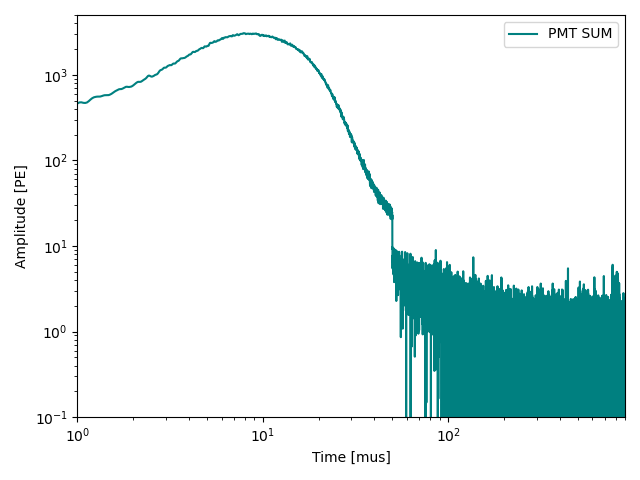

In [94]:
plt.figure()
t_pmt   = np.arange(wf_sum_clean .size) * 25e-3 # sampling period in mus
plt.plot(t_pmt-1000 , wf_sum_clean, label = "PMT SUM", color = "Teal");



plt.semilogy()
plt.semilogx()
plt.xlabel("Time [mus]")
plt.ylabel("Amplitude [PE]")

plt.xlim(1, 900)
plt.ylim(1e-1, 5000)

plt.legend()
plt.tight_layout()

plt.axhline(y=0, color='black', linestyle='--')
